In [1]:
import os
import random
import scipy.io
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from tqdm import tqdm
from HybridKANSRF import HybridColorKAN



In [2]:
number_of_primitives = 3
visible_range = True#Use False to select entire spectrum
include_shadows = True
no_of_epochs = 30
#Visible range of pavia dataset has 66 bands and full spectrum has 103 bands
no_of_bands = 66 if visible_range else 103
output_classes = 9 if include_shadows else 8

In [3]:
hsi = scipy.io.loadmat("PaviaU.mat")
image = hsi["paviaU"]

gt = scipy.io.loadmat("PaviaU_gt.mat")
index = gt["paviaU_gt"]
image  =image[:, :, :no_of_bands]

print(image.shape)
print(index.shape)

(610, 340, 66)
(610, 340)


In [4]:
#Normalizing the image
max_val = np.max(image)
normalized_image = image.astype(np.float32) / max_val

In [5]:

image_for_training = normalized_image[:,:,:no_of_bands]
print(image_for_training.shape)

(610, 340, 66)


In [6]:
x = []
for i in range(len(image_for_training)):
    for j in range(len(image_for_training[0])):
        if (index[i][j] == 0) or (index[i][j] == 9 and (not include_shadows)): #Ignoring all unclassified pixels
            continue
        x.append(image_for_training[i][j])

x = np.asarray(x,dtype=np.float32)
print(x.shape)

(42776, 66)


In [7]:
y = []

for i in range(len(image)):
    for j in range(len(image[0])):
        if index[i][j] == 0 or \
           (index[i][j] == 9 and (not include_shadows)):
            continue

        y.append(index[i][j]-1)

y = np.asarray(y , dtype=np.int64)
y.shape

(42776,)

In [8]:
wavelengths = torch.linspace(
    430, 860, 66,
    dtype=torch.float32
)

In [9]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Using device:", device)


model = HybridColorKAN(
    no_of_bands=no_of_bands,
    number_of_primitives=number_of_primitives,
    output_classes=output_classes,
    wavelengths=wavelengths,
    # RBF bases used to generate the smooth wavelength SRF
    wavelength_num_grids=12,

    # Original FastKAN intensity RBF bases
    intensity_num_grids=8,

    # First experiment:
    # signed smooth wavelength envelope
    nonnegative_srf=False,

    # Keep original FastKAN base path
    use_base_update=True,

    # Same initialization scale as original FastKAN
    spline_weight_init_scale=0.1
).to(device)

print(model)

Using device: cpu
HybridColorKAN(
  (primitives): ModuleList(
    (0-2): 3 x HybridSpectralPrimitive(
      (srf_generator): WavelengthSRFGenerator(
        (wavelength_rbf): GaussianRBF()
      )
      (layernorm): LayerNorm((66,), eps=1e-05, elementwise_affine=True)
      (intensity_rbf): GaussianRBF()
      (spline_linear): SplineLinear(in_features=528, out_features=1, bias=False)
      (base_linear): Linear(in_features=66, out_features=1, bias=True)
    )
  )
  (classifier_dense): Linear(in_features=3, out_features=9, bias=True)
)


In [10]:
print("Bands:", no_of_bands)
print("Wavelength count:", len(wavelengths))
print(
    "Wavelength range:",
    wavelengths.min().item(),
    "to",
    wavelengths.max().item(),
    "nm"
)

assert len(wavelengths) == no_of_bands

with torch.no_grad():
    test_input = torch.randn(2, no_of_bands, device=device)
    test_output = model(test_input)

print("Test output shape:", test_output.shape)

Bands: 66
Wavelength count: 66
Wavelength range: 430.0 to 860.0 nm
Test output shape: torch.Size([2, 9])


In [11]:
from torchinfo import summary
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

model = model.to(device)

summary(
    model,
    input_size=(1, no_of_bands))

optimizer = torch.optim.Adam(
    model.parameters(),)

criterion = nn.CrossEntropyLoss()

x_tensor = torch.tensor( x,dtype=torch.float32)

y_tensor = torch.tensor( y,dtype=torch.long)

batch_size = 32

dataset = TensorDataset(x_tensor,y_tensor)

train_loader = DataLoader(dataset,batch_size=batch_size,shuffle=True)

loss_history = []
accuracy_history = []

for epoch in range(no_of_epochs):

    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for batch_x, batch_y in train_loader:

        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        optimizer.zero_grad()

        output = model(batch_x)

        loss = criterion(output,batch_y)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * batch_x.size(0)

        predictions = torch.argmax(output,dim=1)

        total_correct += ( predictions == batch_y).sum().item()

        total_samples += batch_y.size(0)

    epoch_loss = total_loss / total_samples

    epoch_accuracy = (total_correct / total_samples
    )

    loss_history.append(
        epoch_loss
    )

    accuracy_history.append(
        epoch_accuracy
    )

    print(
        f"Epoch [{epoch+1}/{no_of_epochs}] | "
        f"Loss: {epoch_loss:.4f} | "
        f"Accuracy: {epoch_accuracy:.4f}"
    )

Using device: cpu
Epoch [1/30] | Loss: 1.1531 | Accuracy: 0.5925
Epoch [2/30] | Loss: 0.7356 | Accuracy: 0.7355
Epoch [3/30] | Loss: 0.6685 | Accuracy: 0.7581
Epoch [4/30] | Loss: 0.6390 | Accuracy: 0.7703
Epoch [5/30] | Loss: 0.6203 | Accuracy: 0.7791
Epoch [6/30] | Loss: 0.6073 | Accuracy: 0.7855
Epoch [7/30] | Loss: 0.5966 | Accuracy: 0.7911
Epoch [8/30] | Loss: 0.5882 | Accuracy: 0.7948
Epoch [9/30] | Loss: 0.5802 | Accuracy: 0.7983
Epoch [10/30] | Loss: 0.5729 | Accuracy: 0.8006
Epoch [11/30] | Loss: 0.5659 | Accuracy: 0.8041
Epoch [12/30] | Loss: 0.5590 | Accuracy: 0.8076
Epoch [13/30] | Loss: 0.5511 | Accuracy: 0.8102
Epoch [14/30] | Loss: 0.5454 | Accuracy: 0.8119
Epoch [15/30] | Loss: 0.5387 | Accuracy: 0.8138
Epoch [16/30] | Loss: 0.5337 | Accuracy: 0.8156
Epoch [17/30] | Loss: 0.5285 | Accuracy: 0.8161
Epoch [18/30] | Loss: 0.5240 | Accuracy: 0.8178
Epoch [19/30] | Loss: 0.5203 | Accuracy: 0.8185
Epoch [20/30] | Loss: 0.5162 | Accuracy: 0.8187
Epoch [21/30] | Loss: 0.5131 | 

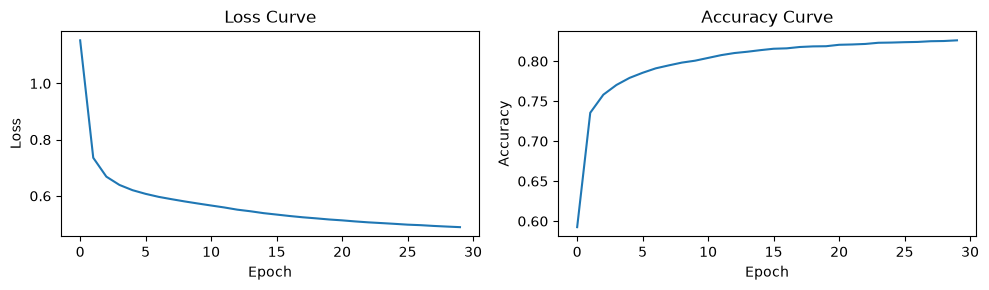

In [12]:
plt.figure(figsize=(10, 3))

plt.subplot(1, 2, 1)
plt.plot(loss_history)
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1, 2, 2)
plt.plot(accuracy_history)
plt.title("Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.tight_layout()
plt.show()

In [13]:
wavelength_np = wavelengths.cpu().numpy()

Primitive 1 SRF shape: (66,)


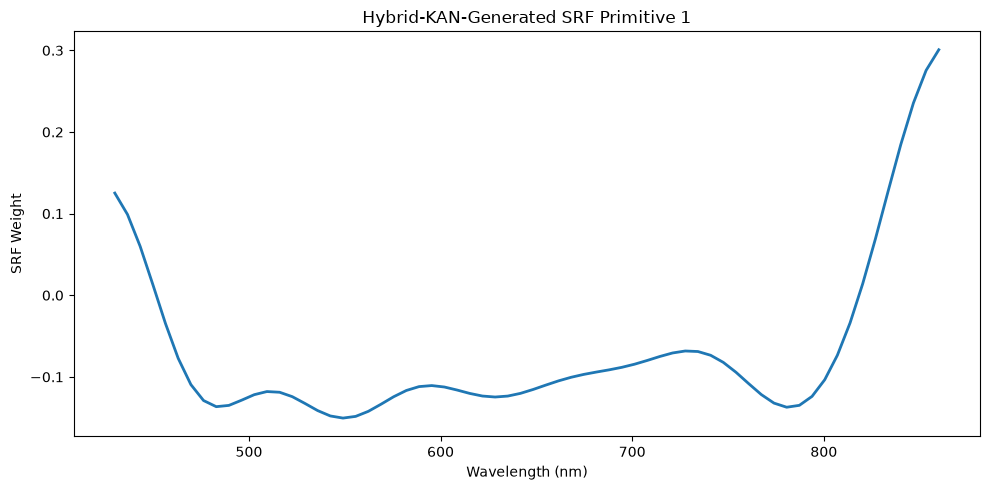

Primitive 2 SRF shape: (66,)


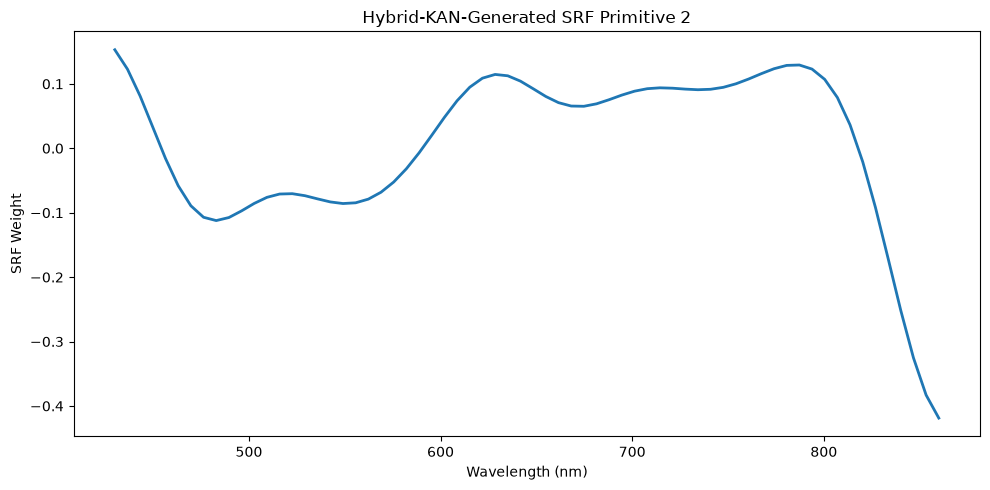

Primitive 3 SRF shape: (66,)


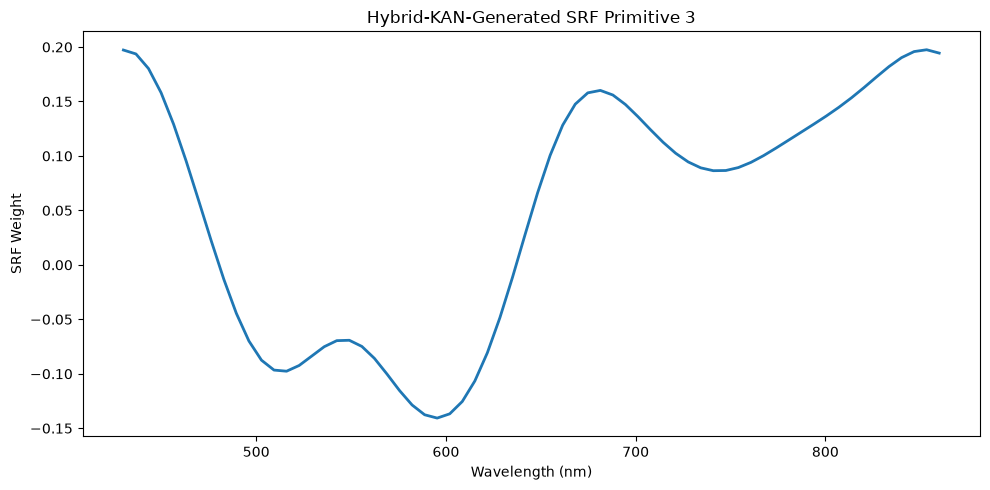

In [14]:
primitive_curves = []

model.eval()

for primitive_no in range(number_of_primitives):

    with torch.no_grad():

        curve = (
            model.primitives[primitive_no]
            .get_srf()
            .cpu()
            .numpy()
        )

    primitive_curves.append(curve)

    print(
        f"Primitive {primitive_no + 1} "
        f"SRF shape: {curve.shape}"
    )

    plt.figure(figsize=(10, 5))

    plt.plot(
        wavelength_np,
        curve,
        linewidth=2
    )

    plt.title(
        f"Hybrid-KAN-Generated SRF "
        f"Primitive {primitive_no + 1}"
    )

    plt.xlabel("Wavelength (nm)")
    plt.ylabel("SRF Weight")
    plt.tight_layout()
    plt.show()

In [15]:
for i ,p in enumerate(primitive_curves):
    print(i+1, f"primitive_{i+1}" , p[0])

1 primitive_1 0.12518433
2 primitive_2 0.15295887
3 primitive_3 0.19722149


In [16]:

for i, (name, parameter) in enumerate(model.named_parameters()):
    if parameter.requires_grad:
        print(i, name, parameter.shape)

0 primitives.0.srf_generator.rbf_coefficients torch.Size([12])
1 primitives.0.srf_generator.base_coefficient torch.Size([1])
2 primitives.0.srf_generator.srf_offset torch.Size([1])
3 primitives.0.layernorm.weight torch.Size([66])
4 primitives.0.layernorm.bias torch.Size([66])
5 primitives.0.spline_linear.weight torch.Size([1, 528])
6 primitives.0.base_linear.weight torch.Size([1, 66])
7 primitives.0.base_linear.bias torch.Size([1])
8 primitives.1.srf_generator.rbf_coefficients torch.Size([12])
9 primitives.1.srf_generator.base_coefficient torch.Size([1])
10 primitives.1.srf_generator.srf_offset torch.Size([1])
11 primitives.1.layernorm.weight torch.Size([66])
12 primitives.1.layernorm.bias torch.Size([66])
13 primitives.1.spline_linear.weight torch.Size([1, 528])
14 primitives.1.base_linear.weight torch.Size([1, 66])
15 primitives.1.base_linear.bias torch.Size([1])
16 primitives.2.srf_generator.rbf_coefficients torch.Size([12])
17 primitives.2.srf_generator.base_coefficient torch.Size(

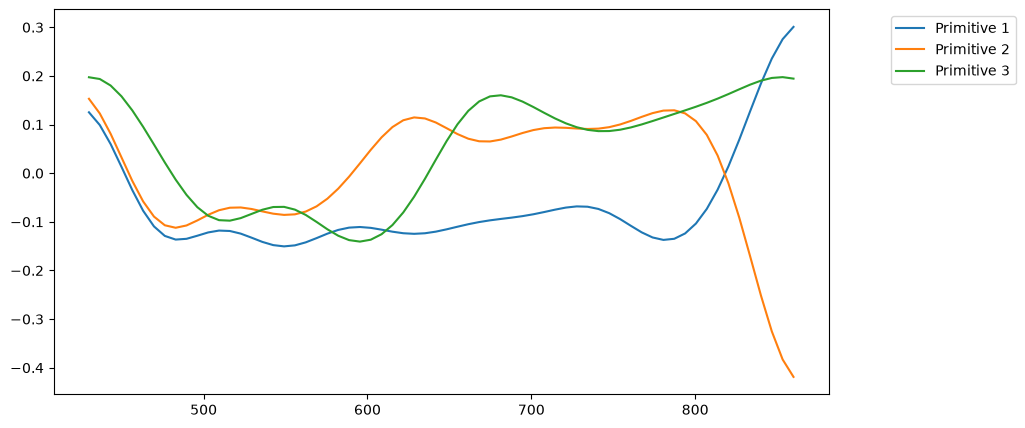

In [17]:

plt.figure(figsize=(10, 5))

for primitive_no in range(number_of_primitives):

    plt.plot(wavelength_np,primitive_curves[primitive_no],label=f"Primitive {primitive_no + 1}")
plt.legend(bbox_to_anchor=(1.25, 1))
plt.show()





==================== Primitive 1 ====================
Normalized SRF weights:
[ 0.12518433  0.09898403  0.05990561  0.01311344 -0.03478046 -0.07726378
 -0.10942723 -0.12897749 -0.13649632 -0.13493656 -0.1285798  -0.12179998
 -0.11798084 -0.11883625 -0.12424301 -0.1325579  -0.14128222 -0.1478729
 -0.15047626 -0.14839903 -0.14221102 -0.13348784 -0.124305   -0.11665011
 -0.11192349 -0.11064504 -0.11241639 -0.116119   -0.12027483 -0.12346222
 -0.12467165 -0.12350778 -0.12019633 -0.11541971 -0.11005413 -0.10490063
 -0.10048143 -0.09694101 -0.09405743 -0.09135424 -0.08828747 -0.08447103
 -0.07988245 -0.0749843  -0.0707078  -0.06828115 -0.06893005 -0.07351839
 -0.08222187 -0.0943296  -0.10824371 -0.12169886 -0.13214548 -0.13717921
 -0.13487005 -0.1238998  -0.10351939 -0.07345186 -0.03389998  0.01424441
  0.06906015  0.12732239  0.18456392  0.2356087   0.27553475  0.30077332]

Intensity-dependent band contributions:
[ 0.02056365 -1.0663927  -1.1037616  -0.25463462  1.155276    1.3319983
  0.1

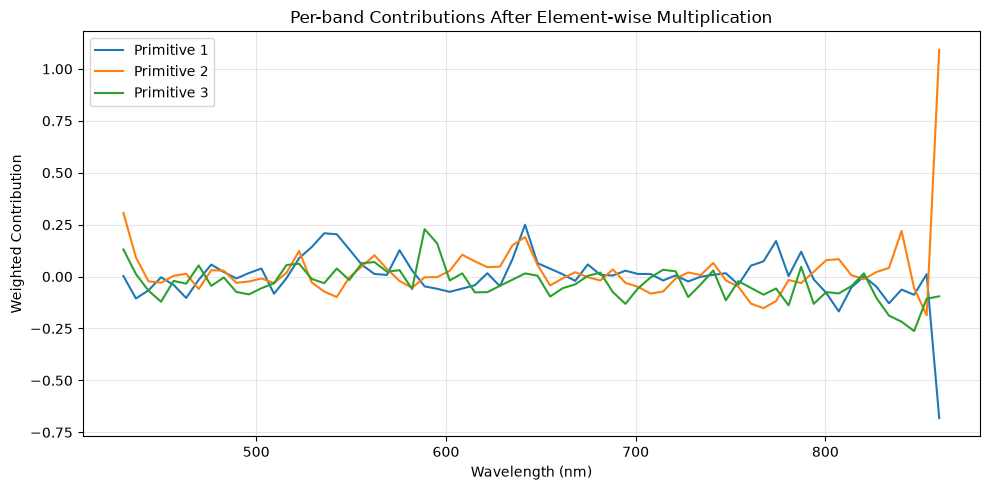

In [18]:

import matplotlib.pyplot as plt
import numpy as np
import torch

primitive_curves = []

model.eval()

# Choose one pixel from the training image
pixel = torch.as_tensor(
    image_for_training[100, 100],
    dtype=torch.float32,
    device=device
)

with torch.no_grad():
    for primitive_no in range(number_of_primitives):

        primitive = model.primitives[primitive_no]

        # 1. Normalized SRF weights
        weights = primitive.get_srf().flatten()

        # 2. Intensity-dependent contribution for each band
        band_contributions = (
            primitive.get_band_contributions(pixel.unsqueeze(0))
            .reshape(-1)
        )

        # 3. Element-wise multiplication
        weighted_contributions = weights * band_contributions

        # Store weighted contributions for plotting
        curve = weighted_contributions.cpu().numpy()
        primitive_curves.append(curve)

        # 4. Print results
        print(f"\n{'=' * 20} Primitive {primitive_no + 1} {'=' * 20}")

        print("Normalized SRF weights:")
        print(weights.cpu().numpy())

        print("\nIntensity-dependent band contributions:")
        print(band_contributions.cpu().numpy())

        print("\nWeighted contributions (weights × contributions):")
        print(curve)

        primitive_output = weighted_contributions.sum().item()
        print(f"\nPrimitive output (sum over bands): {primitive_output:.6f}")


# 5. Plot all primitives together
plt.figure(figsize=(10, 5))

for primitive_no in range(number_of_primitives):
    plt.plot(
        wavelength_np,
        primitive_curves[primitive_no],
        label=f"Primitive {primitive_no + 1}"
    )

plt.xlabel("Wavelength (nm)")
plt.ylabel("Weighted Contribution")
plt.title("Per-band Contributions After Element-wise Multiplication")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [19]:
model.eval()

for k, primitive in enumerate(model.primitives):

    with torch.no_grad():
        weights = primitive.get_srf().detach().cpu().numpy()

    print(f"\nPrimitive {k + 1}")
    print(f"Total weights: {len(weights)}")

    for band, (wavelength, weight) in enumerate(
        zip(wavelength_np, weights), start=1
    ):
        print(
            f"Band {band:3d} | "
            f"Wavelength: {wavelength:.1f} nm | "
            f"Weight: {weight:.6f}"
        )


Primitive 1
Total weights: 66
Band   1 | Wavelength: 430.0 nm | Weight: 0.125184
Band   2 | Wavelength: 436.6 nm | Weight: 0.098984
Band   3 | Wavelength: 443.2 nm | Weight: 0.059906
Band   4 | Wavelength: 449.8 nm | Weight: 0.013113
Band   5 | Wavelength: 456.5 nm | Weight: -0.034780
Band   6 | Wavelength: 463.1 nm | Weight: -0.077264
Band   7 | Wavelength: 469.7 nm | Weight: -0.109427
Band   8 | Wavelength: 476.3 nm | Weight: -0.128977
Band   9 | Wavelength: 482.9 nm | Weight: -0.136496
Band  10 | Wavelength: 489.5 nm | Weight: -0.134937
Band  11 | Wavelength: 496.2 nm | Weight: -0.128580
Band  12 | Wavelength: 502.8 nm | Weight: -0.121800
Band  13 | Wavelength: 509.4 nm | Weight: -0.117981
Band  14 | Wavelength: 516.0 nm | Weight: -0.118836
Band  15 | Wavelength: 522.6 nm | Weight: -0.124243
Band  16 | Wavelength: 529.2 nm | Weight: -0.132558
Band  17 | Wavelength: 535.8 nm | Weight: -0.141282
Band  18 | Wavelength: 542.5 nm | Weight: -0.147873
Band  19 | Wavelength: 549.1 nm | Wei

In [20]:

for i, primitive in enumerate(model.primitives):
    weights = primitive.get_srf().detach()

    print(
        f"Primitive {i + 1}:",
        "number of weights =", weights.numel(),
        "min =", weights.min().item(),
        "max =", weights.max().item(),
        "L2 norm =", torch.norm(weights).item()
    )

print("Number of bands:", no_of_bands)
print("Number of wavelength values:", len(wavelengths))


Primitive 1: number of weights = 66 min = -0.15047626197338104 max = 0.3007733225822449 L2 norm = 0.9999999403953552
Primitive 2: number of weights = 66 min = -0.4187992215156555 max = 0.15295886993408203 L2 norm = 1.0
Primitive 3: number of weights = 66 min = -0.14065396785736084 max = 0.1974814534187317 L2 norm = 1.0
Number of bands: 66
Number of wavelength values: 66


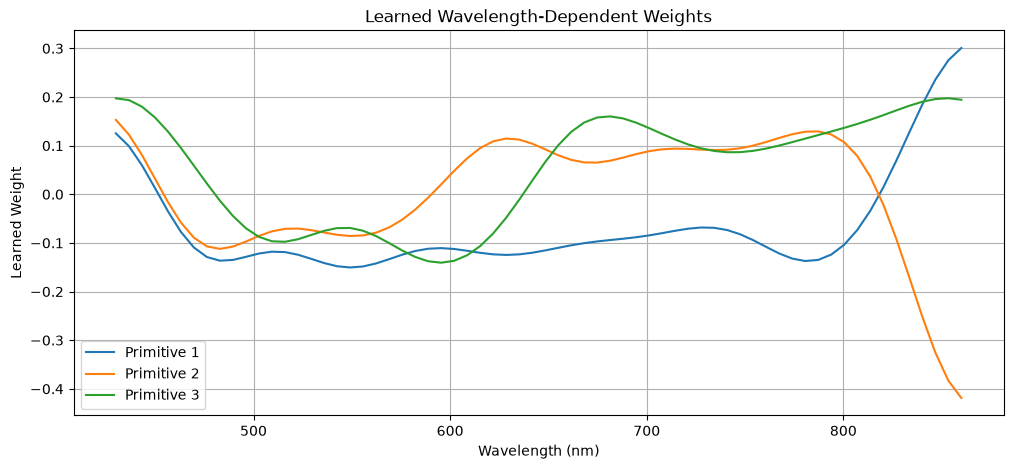

In [21]:
wavelength_np = wavelengths.detach().cpu().numpy()

model.eval()

plt.figure(figsize=(12, 5))

for k, primitive in enumerate(model.primitives):
    with torch.no_grad():
        weights = primitive.get_srf().detach().cpu().numpy()

    plt.plot(
        wavelength_np,
        weights,
        label=f"Primitive {k + 1}"
    )

plt.xlabel("Wavelength (nm)")
plt.ylabel("Learned Weight")
plt.title("Learned Wavelength-Dependent Weights")
plt.legend()
plt.legend()
plt.grid(True)
plt.show()

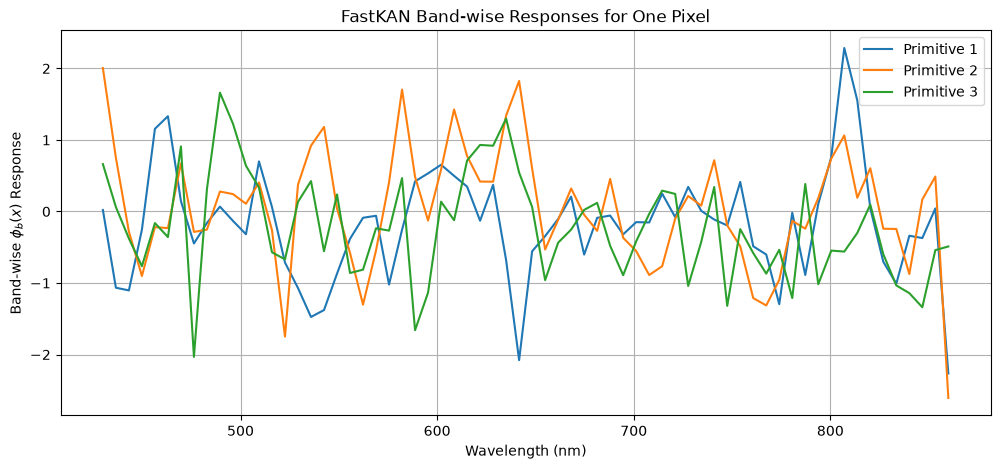

In [22]:
# Select one representative pixel from the image
pixel = torch.tensor(
    image_for_training[100, 100],
    dtype=torch.float32,
    device=device
).unsqueeze(0)

model.eval()

plt.figure(figsize=(12, 5))

with torch.no_grad():
    for k, primitive in enumerate(model.primitives):

        # Shape: (1, 1, 103) when using 103 bands
        phi = primitive.get_band_contributions(pixel)

        # One response value per band
        phi = phi[0, 0, :].cpu().numpy()

        plt.plot(
            wavelength_np,
            phi,
            label=f"Primitive {k + 1}"
        )

plt.xlabel("Wavelength (nm)")
plt.ylabel(r"Band-wise $\phi_b(x)$ Response")
plt.title(r"FastKAN Band-wise Responses for One Pixel")
plt.legend()
plt.grid(True)
plt.show()

In [23]:
model_name = (
    f'{no_of_bands}bands_'f'{number_of_primitives}primitives_' f'{"with_shadow" if include_shadows else "without_shadow"}_' f'Hybridnew_version__random_init_')
print(model_name)

66bands_3primitives_with_shadow_Hybridnew_version__random_init_


In [24]:
print(model_name)

66bands_3primitives_with_shadow_Hybridnew_version__random_init_


In [25]:
torch.save(model.state_dict(), f"{model_name}.pth")

In [26]:
model = HybridColorKAN(
    no_of_bands=no_of_bands,
    number_of_primitives=number_of_primitives,
    output_classes=output_classes,
    wavelengths= wavelengths,

    # Same values used while training
    wavelength_num_grids=12,
    intensity_num_grids=8,
    nonnegative_srf=False,
    use_base_update=True,
    spline_weight_init_scale=0.1
).to(device)


model.load_state_dict(
    torch.load(
        f"{model_name}.pth",
        weights_only=True
    )
)

model.eval()

HybridColorKAN(
  (primitives): ModuleList(
    (0-2): 3 x HybridSpectralPrimitive(
      (srf_generator): WavelengthSRFGenerator(
        (wavelength_rbf): GaussianRBF()
      )
      (layernorm): LayerNorm((66,), eps=1e-05, elementwise_affine=True)
      (intensity_rbf): GaussianRBF()
      (spline_linear): SplineLinear(in_features=528, out_features=1, bias=False)
      (base_linear): Linear(in_features=66, out_features=1, bias=True)
    )
  )
  (classifier_dense): Linear(in_features=3, out_features=9, bias=True)
)

In [27]:
def predict_image():
    x_pred = image_for_training.reshape(-1, no_of_bands)

    print("Prediction Input Shape:", x_pred.shape)
    print("Predicting...")

    x_pred = torch.tensor( x_pred,dtype=torch.float32, device=device)

    model.eval()

    with torch.no_grad():

        primitive_outputs = [primtive(x_pred) for primtive in model.primitives]
        prediction = torch.cat(primitive_outputs,dim=1)

    predicted_image = prediction.cpu().numpy().reshape(
        image.shape[0],
        image.shape[1],
        number_of_primitives
    )

    return predicted_image
def normalize_images(predicted_image, channels):

    global_min = np.min(predicted_image)
    global_max = np.max(predicted_image)

    global_minmax_image = (
        (predicted_image - global_min) /
        (global_max - global_min + 1e-8)
    )
    channel_minmax_image = np.zeros_like(
        predicted_image,
        dtype=np.float32
    )

    for i in range(predicted_image.shape[-1]):

        channel = predicted_image[:, :, i]

        channel_min = np.min(channel)
        channel_max = np.max(channel)

        channel_minmax_image[:, :, i] = (
            (channel - channel_min) /
            (channel_max - channel_min + 1e-8)
        )
    clipped_image = np.clip(
        predicted_image,
        0,
        1
    )
    c1, c2, c3 = [channel - 1 for channel in channels]

    rgb_global_minmax = np.dstack((
        global_minmax_image[:, :, c1],
        global_minmax_image[:, :, c2],
        global_minmax_image[:, :, c3]
    ))

    rgb_channelwise = np.dstack((
        channel_minmax_image[:, :, c1],
        channel_minmax_image[:, :, c2],
        channel_minmax_image[:, :, c3]
    ))

    rgb_clipped = np.dstack((
        clipped_image[:, :, c1],
        clipped_image[:, :, c2],
        clipped_image[:, :, c3]
    ))

    return [
        rgb_global_minmax,
        rgb_channelwise,
        rgb_clipped
    ]


Prediction Input Shape: (207400, 66)
Predicting...


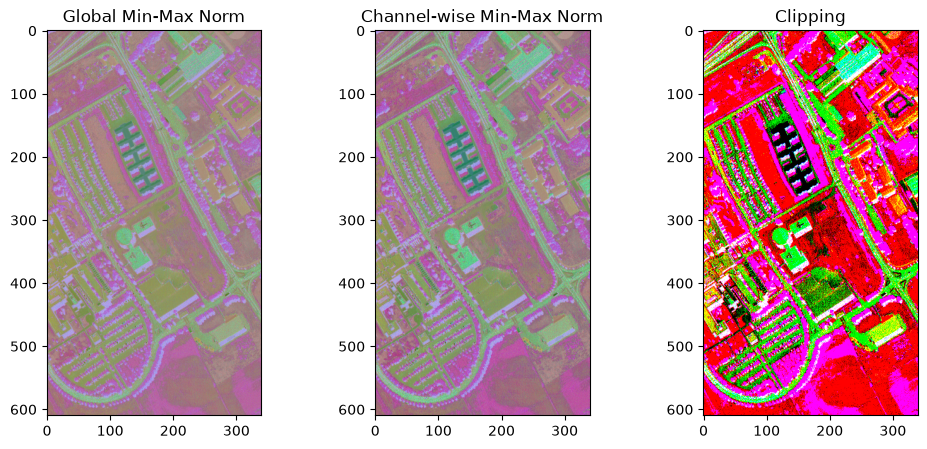

In [28]:
channels = [1, 2, 3]

predicted_image = predict_image()

normalized_images = normalize_images(
    predicted_image,
    channels
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(normalized_images[0])
plt.title("Global Min-Max Norm")

plt.subplot(1, 3, 2)
plt.imshow(normalized_images[1])
plt.title("Channel-wise Min-Max Norm")

plt.subplot(1, 3, 3)
plt.imshow(normalized_images[2])
plt.title("Clipping")

plt.show()

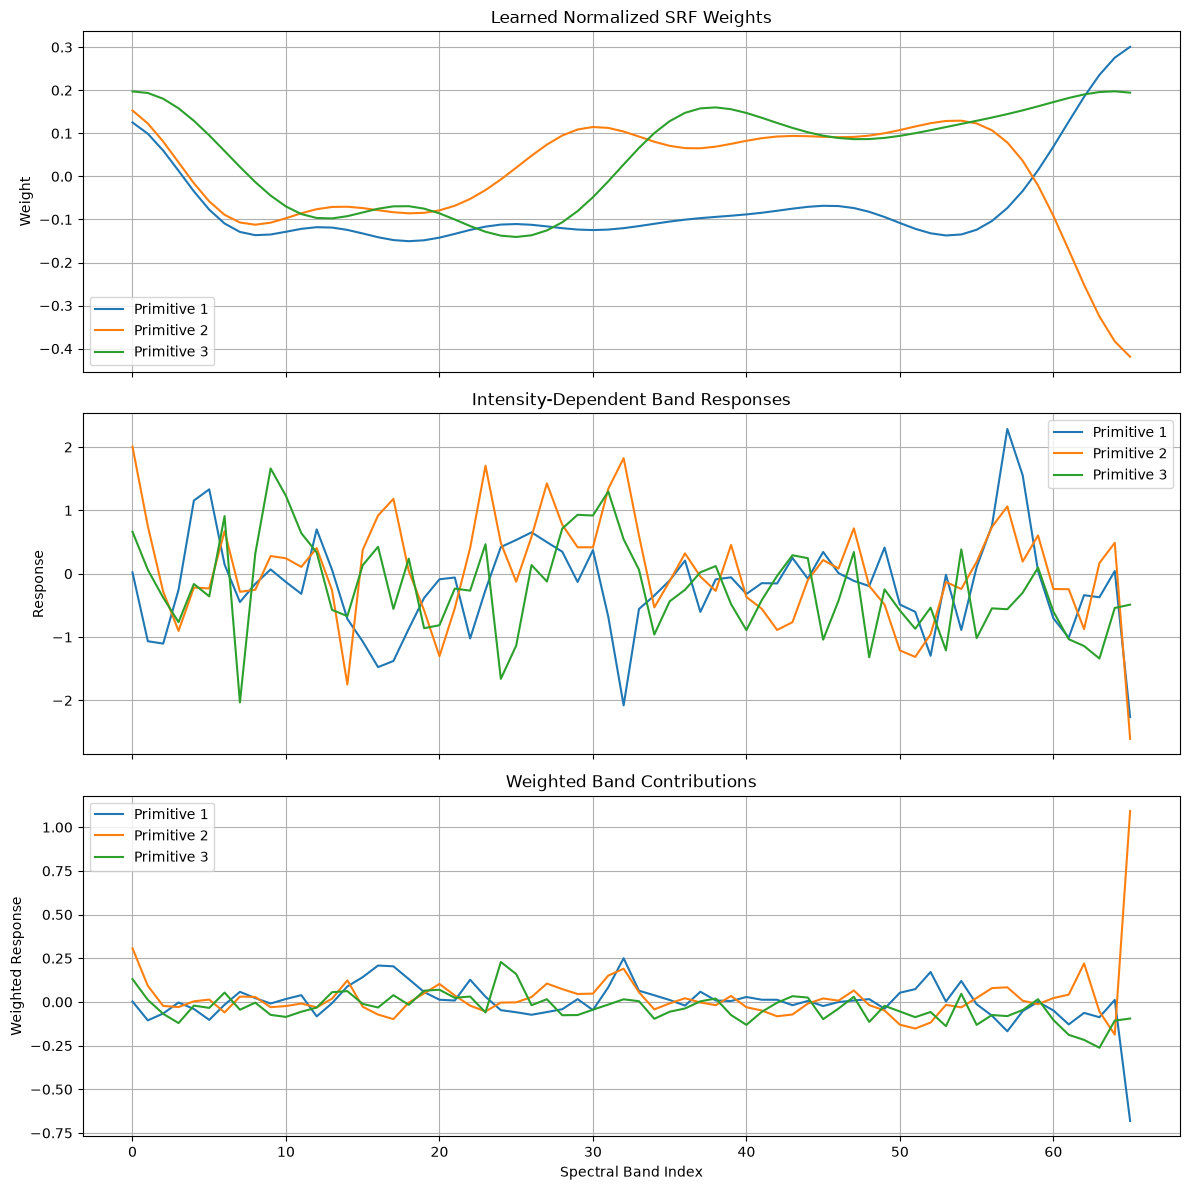

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import torch

pixel = torch.as_tensor(
    image_for_training[100, 100],
    dtype=torch.float32,
    device=device
).reshape(1, -1)

band_indices = np.arange(no_of_bands)

model.eval()

fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 12),
    sharex=True
)

with torch.no_grad():
    for k, primitive in enumerate(model.primitives):

        weights = primitive.get_srf().detach()

        phi = primitive.get_band_contributions(pixel)[0, 0, :]

        weighted_phi = weights * phi

        axes[0].plot(
            band_indices,
            weights.cpu().numpy(),
            label=f"Primitive {k + 1}"
        )

        axes[1].plot(
            band_indices,
            phi.cpu().numpy(),
            label=f"Primitive {k + 1}"
        )

        axes[2].plot(
            band_indices,
            weighted_phi.cpu().numpy(),
            label=f"Primitive {k + 1}"
        )

axes[0].set_title("Learned Normalized SRF Weights")
axes[0].set_ylabel("Weight")

axes[1].set_title("Intensity-Dependent Band Responses")
axes[1].set_ylabel("Response")

axes[2].set_title("Weighted Band Contributions")
axes[2].set_ylabel("Weighted Response")
axes[2].set_xlabel("Spectral Band Index")

for ax in axes:
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

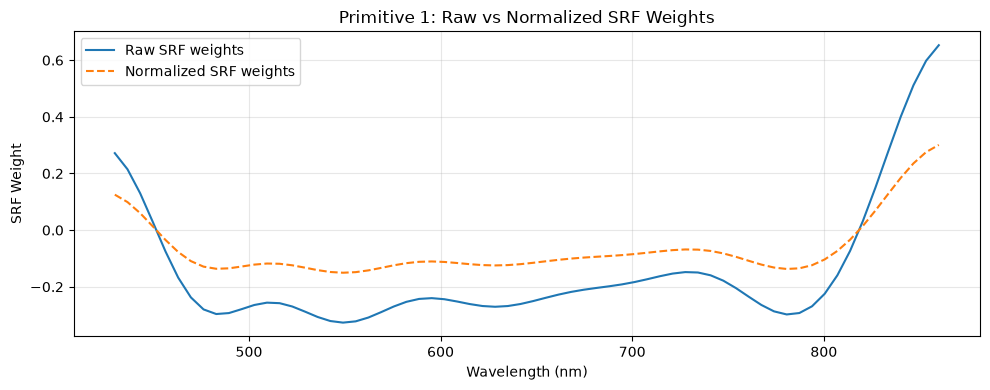

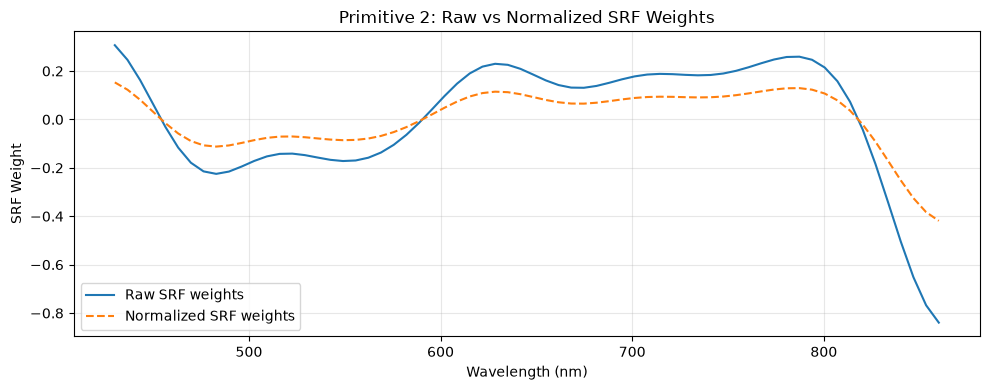

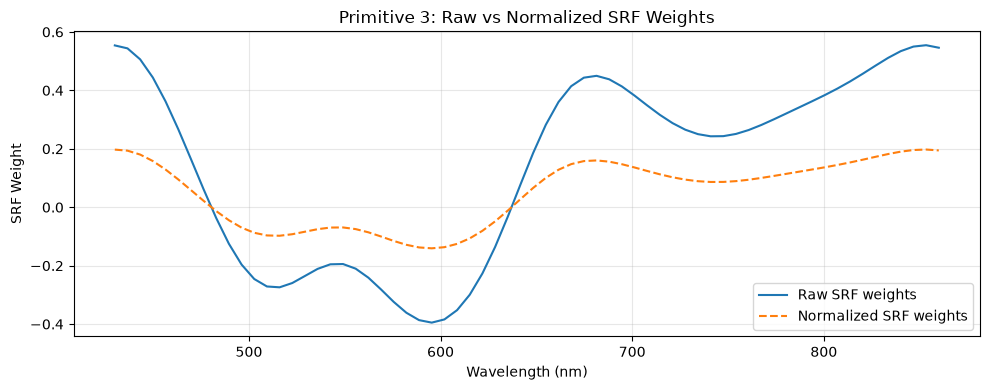

In [30]:
import matplotlib.pyplot as plt

model.eval()

with torch.no_grad():
    for i, primitive in enumerate(model.primitives):

        raw_weights = (
            primitive.srf_generator.get_raw_srf()
            .detach().cpu().flatten().numpy()
        )

        normalized_weights = (
            primitive.get_srf()
            .detach().cpu().flatten().numpy()
        )

        plt.figure(figsize=(10, 4))

        plt.plot(
            wavelength_np,
            raw_weights,
            label="Raw SRF weights"
        )

        plt.plot(
            wavelength_np,
            normalized_weights,
            label="Normalized SRF weights",
            linestyle="--"
        )

        plt.xlabel("Wavelength (nm)")
        plt.ylabel("SRF Weight")
        plt.title(f"Primitive {i + 1}: Raw vs Normalized SRF Weights")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()


Primitive 1 Raw SRF shape: (66,)
Raw SRF weights:
[ 0.27174193  0.21486805  0.13003917  0.0284658  -0.07549913 -0.16771914
 -0.23753744 -0.2799759  -0.29629725 -0.2929114  -0.27911258 -0.26439542
 -0.25610507 -0.25796193 -0.2696986  -0.28774798 -0.30668616 -0.32099277
 -0.326644   -0.32213488 -0.30870235 -0.28976664 -0.26983315 -0.25321642
 -0.24295618 -0.240181   -0.24402614 -0.2520635  -0.2610847  -0.26800367
 -0.27062905 -0.2681026  -0.2609143  -0.25054553 -0.23889828 -0.22771141
 -0.21811849 -0.21043319 -0.20417371 -0.19830579 -0.19164865 -0.18336418
 -0.17340358 -0.16277099 -0.15348785 -0.14822024 -0.14962883 -0.15958889
 -0.17848183 -0.2047645  -0.23496835 -0.2641759  -0.28685275 -0.29777962
 -0.29276705 -0.26895356 -0.2247131  -0.15944448 -0.07358786  0.03092083
  0.14991125  0.2763831   0.40063924  0.5114439   0.59811276  0.65289897]


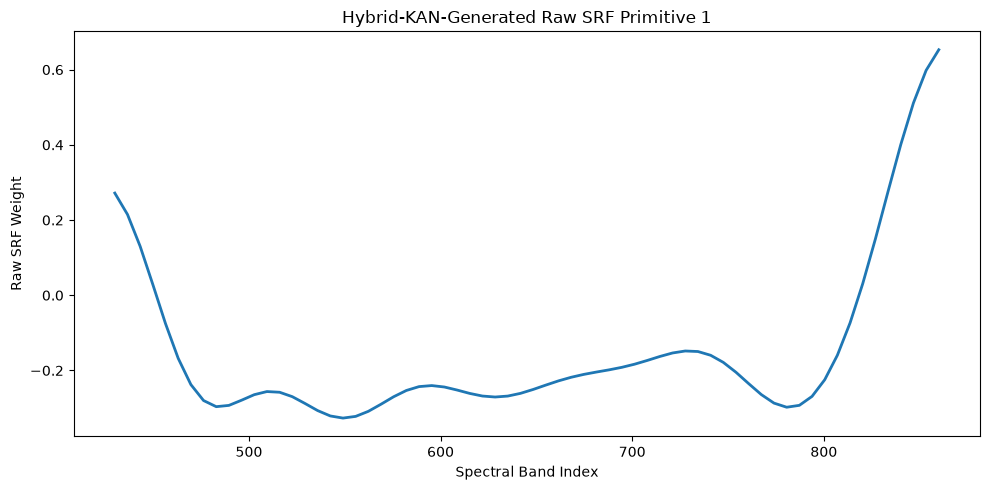

Primitive 2 Raw SRF shape: (66,)
Raw SRF weights:
[ 0.30659488  0.2460924   0.1622702   0.06531555 -0.03182919 -0.11642823
 -0.17886926 -0.2146538  -0.22492011 -0.2154695  -0.19474767 -0.17148215
 -0.15266372 -0.14232512 -0.1412568  -0.14752345 -0.15747437 -0.16688408
 -0.1719019  -0.1696125  -0.15817653 -0.13669045 -0.10500347 -0.06369918
 -0.01430848  0.04038258  0.09620514  0.14792086  0.19006087  0.21812628
  0.22977498  0.22555669  0.20890561  0.18535307  0.16119334  0.1420089
  0.1314677   0.1306985   0.13835289  0.15127826  0.16557147  0.17770374
  0.18541127  0.18813853  0.18696606  0.18411417  0.1822189   0.1835977
  0.18967868  0.20068203  0.21556596  0.23218018  0.24751464  0.25791195
  0.25914845  0.24642073  0.21443929  0.15793617  0.07280458 -0.04219738
 -0.18368305 -0.34256837 -0.50448185 -0.65192217 -0.767822   -0.83945245]


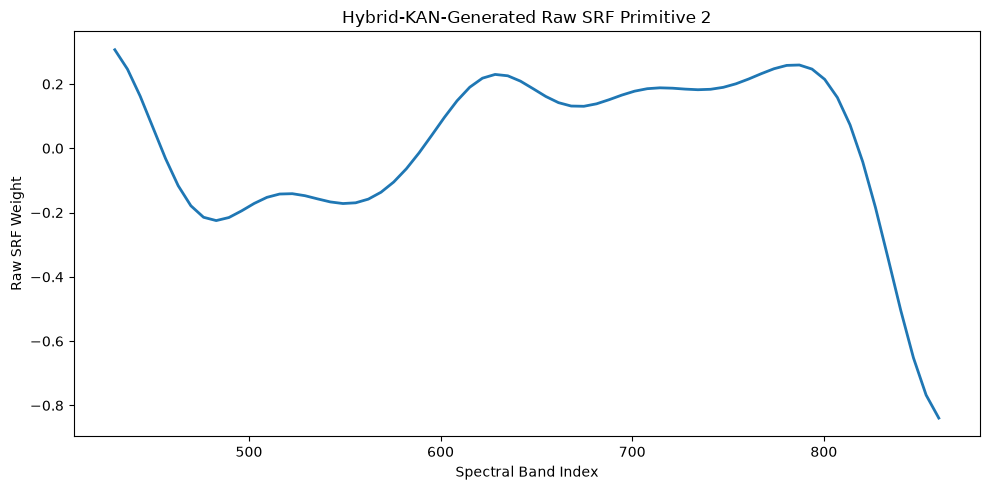

Primitive 3 Raw SRF shape: (66,)
Raw SRF weights:
[ 0.5538385   0.5437422   0.5060818   0.4439506   0.36246613  0.26759487
  0.16538814  0.06180387 -0.03711092 -0.12512791 -0.19624925 -0.24570423
 -0.27123517 -0.27412444 -0.2594408  -0.23526058 -0.21100822 -0.19537428
 -0.19440615 -0.21028173 -0.24105823 -0.28139612 -0.32397917 -0.36117497
 -0.38642123 -0.39498526 -0.38402948 -0.35223526 -0.29942048 -0.22651854
 -0.13597709 -0.03230835  0.07771175  0.18555829  0.28226435  0.36013263
  0.4142798   0.44343308  0.44975674  0.43785766  0.41343015  0.38204244
  0.34839472  0.316096    0.28778902  0.2653736   0.2501427   0.2427766
  0.24326497  0.25086752  0.26421028  0.2815441   0.3011133   0.3215313
  0.34204236  0.36259118  0.3836862   0.40609518  0.43044984  0.45682842
  0.484398    0.51120555  0.534242    0.54986423  0.5545685   0.54593486]


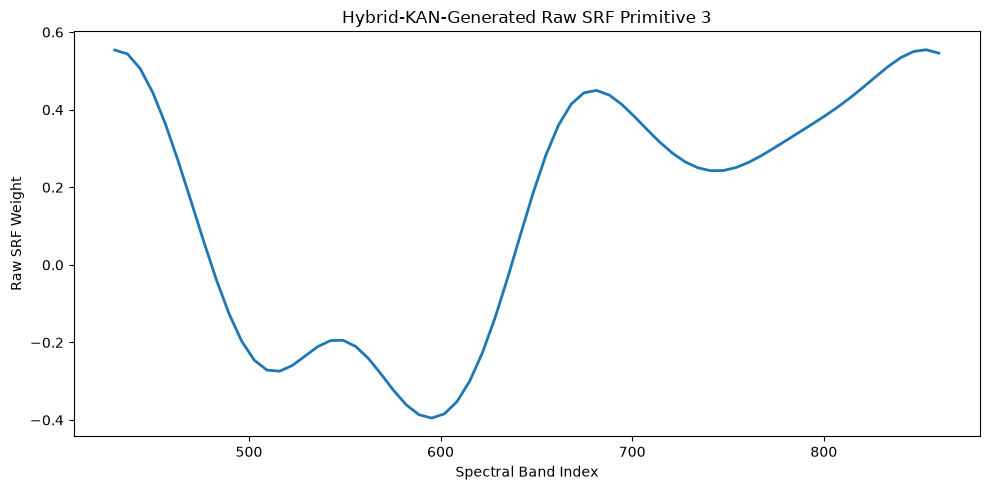

In [31]:

primitive_curves = []

model.eval()

for primitive_no in range(number_of_primitives):

    with torch.no_grad():
        curve = (
            model.primitives[primitive_no]
            .srf_generator
            .get_raw_srf()
            .detach()
            .cpu()
            .numpy()
        )

    primitive_curves.append(curve)

    print(
        f"Primitive {primitive_no + 1} "
        f"Raw SRF shape: {curve.shape}"
    )

    print("Raw SRF weights:")
    print(curve)

    plt.figure(figsize=(10, 5))

    plt.plot(
        wavelength_np,
        curve,
        linewidth=2
    )

    plt.title(
        f"Hybrid-KAN-Generated Raw SRF "
        f"Primitive {primitive_no + 1}"
    )

    plt.xlabel("Spectral Band Index")
    plt.ylabel("Raw SRF Weight")
    plt.tight_layout()
    plt.show()


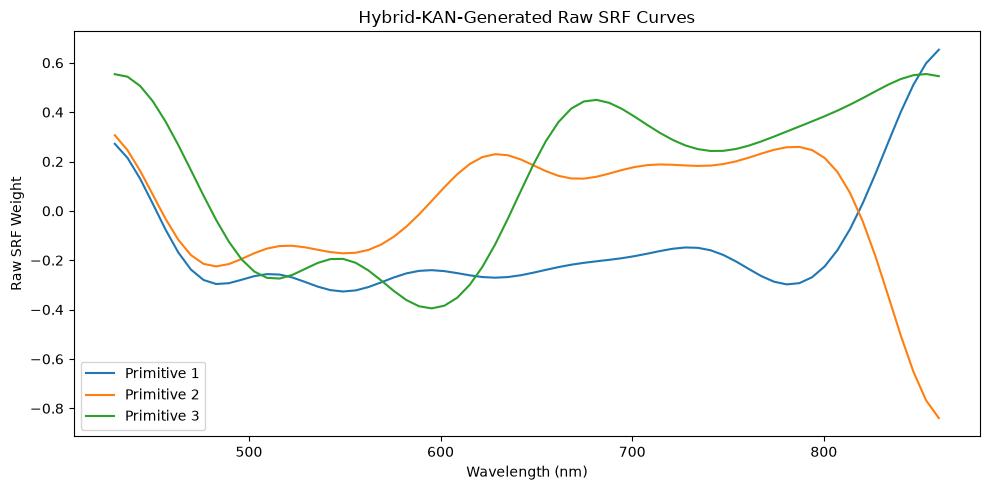

In [32]:
plt.figure(figsize=(10, 5))

for primitive_no in range(number_of_primitives):
    plt.plot(
        wavelength_np,
        primitive_curves[primitive_no],
        label=f"Primitive {primitive_no + 1}"
    )

plt.title("Hybrid-KAN-Generated Raw SRF Curves")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Raw SRF Weight")
plt.legend()
plt.tight_layout()
plt.show()